In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import matplotlib.pyplot as plt

미분(Differential)

<img src="./differential1.png" width="300" align="left" />

diff1(미분할 함수, 미분할 값, 수치 미분을 위해 지정하는 값)

In [2]:
def diff1(f, x, h=1e-6):
    return (f(x + h) - f(x)) / h

미분(Differential): 대칭 파생

<img src="./differential2.png" width="300" align="left" />

In [3]:
def diff2(f, x, h=1e-6):
    return (f(x + h) - f(x - h)) / (2 * h)

In [4]:
def f1(x):
    return x ** 2

In [5]:
print(diff1(f1, 1))
print(diff2(f1, 1))

2.0000009999243673
2.000000000002


In [6]:
f2 = lambda x: x ** 2

In [7]:
print(diff1(f2, 1))
print(diff2(f2, 1))

2.0000009999243673
2.000000000002


## 경사 하강법 클래스를 만든다.

In [8]:
class Descent:
    def __init__(self, lr, h=1e-6):
        self.lr = lr # 학습율
        self.h = h # 수치 미분을 위해 지정하는 값, 작을 수록 더 정교한 미분을 실행한다.
        
    def __str__(self):
        return f'경사 하강법(학습율 = {self.lr})'
    
    # 미분을 실행하는 함수
    def diff(self, f, x):
        return (f(x + self.h) - f(x - self.h)) / (2 * self.h)
    
    # 미분을 실행하는 함수를 실행해서 경사 하강법 업데이트 함수
    def update(self, f, x):
        dx = self.diff(f, x)
        return x - self.lr * dx

## 경사 하강법을 실행하고 결과를 시각화하는 클래스를 만든다.

In [66]:
class OneVariableFunc:
    def __init__(self, func, optimizer):
        self.func = func # 최적화 할 함수
        self.optimizer = optimizer # 경사 하강법 클래스, 모멘텀 클래스
        
    # 옵티마이저를 실행하는 함수, epoch는 학습 횟수를 의미한다.
    def run(self, x, epoch):
        self.xs = [x]
        for i in range(epoch):
            self.xs.append(self.optimizer.update(self.func, self.xs[-1]))
        print(f'{x}에서 시작해서 {epoch}번 {self.optimizer}을(를) 적용한 결과는 {self.xs[-1]} 입니다.')
        
    # 시각화 함수
    def visualize(self, xs, xe):
        plt.figure(figsize=[8, 6])
        # 2차원 곡선 시각화
        x = np.linspace(xs, xe, int((xe - xs) * 100))
        y = [self.func(i) for i in x]
        plt.plot(x, y, 'r--')
        # 경사 하강법으로 이동하는 위치 시각화
        ys = [self.func(i) for i in self.xs]
        plt.plot(self.xs, ys, 'bo')
        plt.show()
        
    # 경사 하강법을 실행한 히스토리를 출력하는 함수
    def history(self):
        for i in range(len(self.xs[1:])):
            print(f'{i + 1:3d}번 {self.optimizer}를 적용한 결과는 {self.xs[i + 1]:.8f} 입니다.')

## 경사 하강법을 실행한다.

경사 하강법(학습율 = 0.06)
3에서 시작해서 50번 경사 하강법(학습율 = 0.06)을(를) 적용한 결과는 0.005026374717448736 입니다.


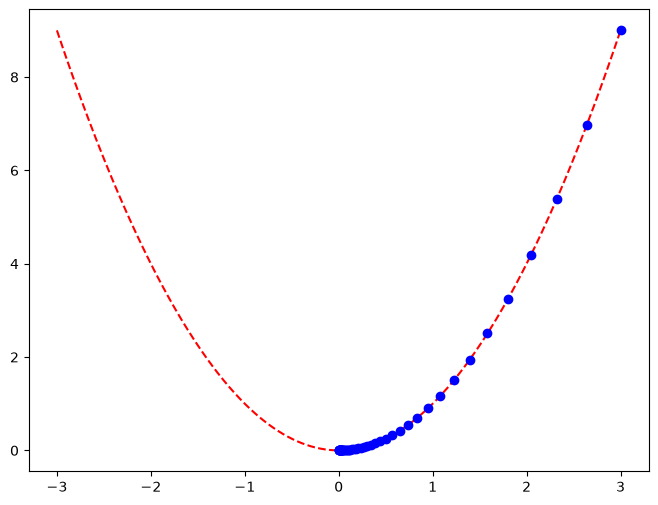

  1번 경사 하강법(학습율 = 0.06)를 적용한 결과는 2.64000000 입니다.
  2번 경사 하강법(학습율 = 0.06)를 적용한 결과는 2.32320000 입니다.
  3번 경사 하강법(학습율 = 0.06)를 적용한 결과는 2.04441600 입니다.
  4번 경사 하강법(학습율 = 0.06)를 적용한 결과는 1.79908608 입니다.
  5번 경사 하강법(학습율 = 0.06)를 적용한 결과는 1.58319575 입니다.
  6번 경사 하강법(학습율 = 0.06)를 적용한 결과는 1.39321226 입니다.
  7번 경사 하강법(학습율 = 0.06)를 적용한 결과는 1.22602679 입니다.
  8번 경사 하강법(학습율 = 0.06)를 적용한 결과는 1.07890357 입니다.
  9번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.94943515 입니다.
 10번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.83550293 입니다.
 11번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.73524258 입니다.
 12번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.64701347 입니다.
 13번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.56937185 입니다.
 14번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.50104723 입니다.
 15번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.44092156 입니다.
 16번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.38801097 입니다.
 17번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.34144966 입니다.
 18번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.30047570 입니다.
 19번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.26441861 입니다.
 20번 경사 하강법(학습율 = 0.06)를 적용한 결과는 0.23268838 입니다.
 21번 경사 하강법(학습율 = 0.

In [67]:
optimizer = Descent(0.06)
print(optimizer)
f = lambda x: x ** 2
ex = OneVariableFunc(f, optimizer)
ex.run(3, 50)
ex.visualize(-3, 3)
ex.history()

경사 하강법(학습율 = 0.001)
3에서 시작해서 50번 경사 하강법(학습율 = 0.001)을(를) 적용한 결과는 2.7142404539767213 입니다.


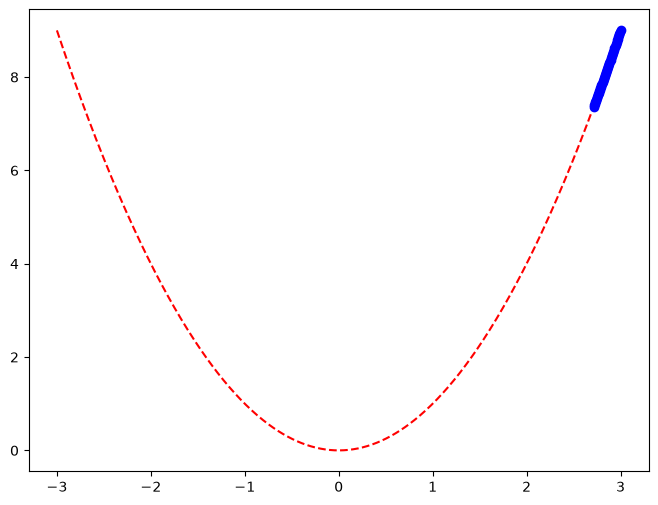

  1번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.99400000 입니다.
  2번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.98801200 입니다.
  3번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.98203598 입니다.
  4번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.97607190 입니다.
  5번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.97011976 입니다.
  6번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.96417952 입니다.
  7번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.95825116 입니다.
  8번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.95233466 입니다.
  9번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.94642999 입니다.
 10번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.94053713 입니다.
 11번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.93465606 입니다.
 12번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.92878674 입니다.
 13번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.92292917 입니다.
 14번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.91708331 입니다.
 15번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.91124915 입니다.
 16번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.90542665 입니다.
 17번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.89961579 입니다.
 18번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.89381656 입니다.
 19번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.88802893 입니다.
 20번 경사 하강법(학습율 = 0.001)를 적용한 결과는 2.88225287 입니다.


In [81]:
optimizer = Descent(0.001)
print(optimizer)
f = lambda x: x ** 2
ex = OneVariableFunc(f, optimizer)
ex.run(3, 50)
ex.visualize(-3, 3)
ex.history()

경사 하강법(학습율 = 1)
3에서 시작해서 50번 경사 하강법(학습율 = 1)을(를) 적용한 결과는 3.000000042632564 입니다.


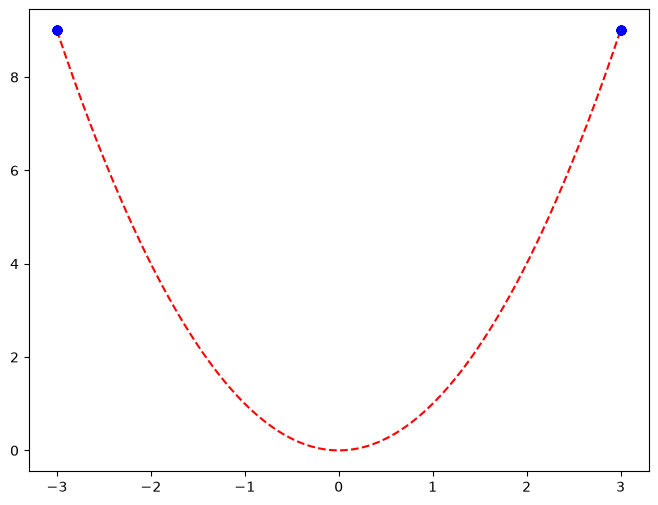

  1번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000000 입니다.
  2번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000000 입니다.
  3번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000000 입니다.
  4번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000000 입니다.
  5번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000000 입니다.
  6번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
  7번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000001 입니다.
  8번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
  9번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000001 입니다.
 10번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
 11번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000001 입니다.
 12번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
 13번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000001 입니다.
 14번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
 15번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000001 입니다.
 16번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000001 입니다.
 17번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000002 입니다.
 18번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000002 입니다.
 19번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000002 입니다.
 20번 경사 하강법(학습율 = 1)를 적용한 결과는 3.00000002 입니다.
 21번 경사 하강법(학습율 = 1)를 적용한 결과는 -3.00000002 입니다.
 22번 경사 하강법(학습율 = 1)를 적

In [82]:
optimizer = Descent(1)
print(optimizer)
f = lambda x: x ** 2
ex = OneVariableFunc(f, optimizer)
ex.run(3, 50)
ex.visualize(-3, 3)
ex.history()

가운데 평탄한(기울기가 0인) 구간이 있는 함수

In [70]:
def ff(x):
    if x > 1:
        return x ** 2
    elif x > 0.2:
        return 1
    else:
        return 20 * x ** 2

2.5에서 시작해서 50번 경사 하강법(학습율 = 0.01)을(를) 적용한 결과는 0.98705076749944 입니다.


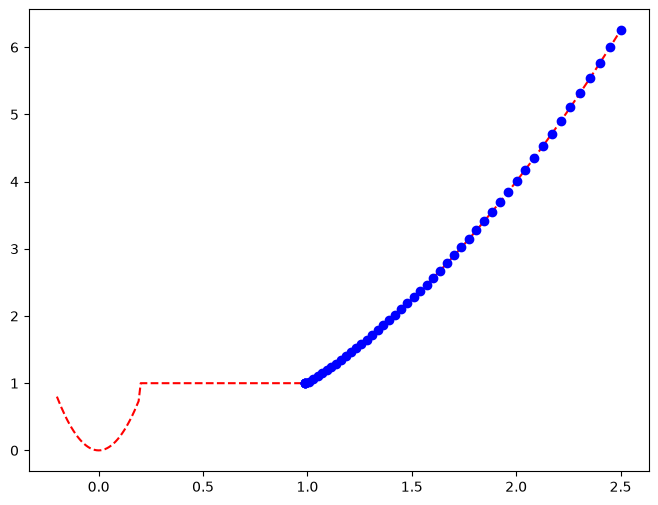

  1번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.45000000 입니다.
  2번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.40100000 입니다.
  3번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.35298000 입니다.
  4번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.30592040 입니다.
  5번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.25980199 입니다.
  6번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.21460595 입니다.
  7번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.17031383 입니다.
  8번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.12690756 입니다.
  9번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.08436941 입니다.
 10번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.04268202 입니다.
 11번 경사 하강법(학습율 = 0.01)를 적용한 결과는 2.00182838 입니다.
 12번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.96179181 입니다.
 13번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.92255597 입니다.
 14번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.88410485 입니다.
 15번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.84642276 입니다.
 16번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.80949430 입니다.
 17번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.77330442 입니다.
 18번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.73783833 입니다.
 19번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.70308156 입니다.
 20번 경사 하강법(학습율 = 0.01)를 적용한 결과는 1.66901993 입니다.
 21번 경사 하강법(학습율 = 0.

In [78]:
optimizer = Descent(0.01)
ex = OneVariableFunc(ff, optimizer)
ex.run(2.5, 50)
ex.visualize(-0.2, 2.5)
ex.history()

# 경사 하강법 모멘텀 클래스를 만든다.

In [89]:
class Momentum:
    def __init__(self, mo, lr, h=1e-6):
        self.previous = 0 # 이전에 얼마나 움직였나 기억하는 변수
        self.mo = mo # 관성 계수, 보통 0.8이나 0.9 정도를 사용한다.
        self.lr = lr
        self.h = h
        
    def __str__(self):
        return f'모멘텀 경사 하강법(학습율 = {self.lr})'
    
    def diff(self, f, x):
        # return (f(x + self.h) - f(x - self.h)) / (2 * self.h)
        return (f(x + self.h) - f(x)) / self.h
    
    def update(self, f, x):
        # dx = self.diff(f, x) # 경사 하강법
        # return x - self.lr * dx # 경사 하강법
        
        # 이전에 움직인 거리를 계산한다.
        dx = self.previous * self.mo - self.lr * self.diff(f, x)
        # 이전에 움직인 거리를 저장한다.
        self.previous = dx
        return x + dx

2.5에서 시작해서 15번 모멘텀 경사 하강법(학습율 = 0.009)을(를) 적용한 결과는 0.13550094944127794 입니다.


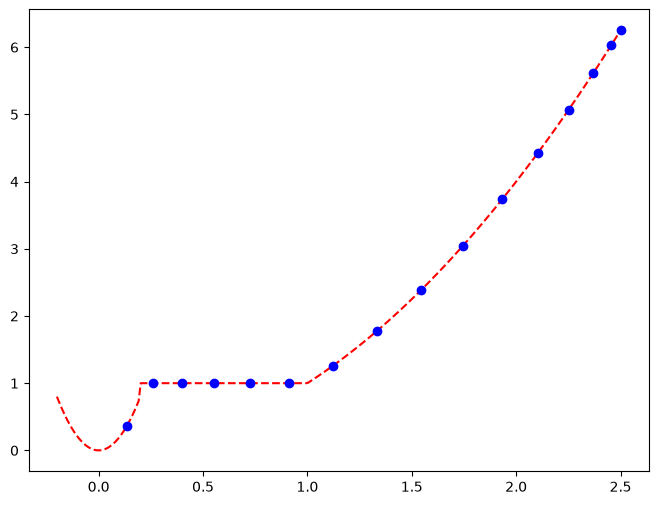

  1번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 2.45499999 입니다.
  2번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 2.37030997 입니다.
  3번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 2.25142337 입니다.
  4번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 2.10389980 입니다.
  5번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 1.93325838 입니다.
  6번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 1.74488244 입니다.
  7번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 1.54393620 입니다.
  8번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 1.33529372 입니다.
  9번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 1.12348020 입니다.
 10번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.91262538 입니다.
 11번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.72285604 입니다.
 12번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.55206363 입니다.
 13번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.39835046 입니다.
 14번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.26000861 입니다.
 15번 모멘텀 경사 하강법(학습율 = 0.009)를 적용한 결과는 0.13550095 입니다.


In [103]:
optimizer = Momentum(0.9, 0.009)
ex = OneVariableFunc(ff, optimizer)
ex.run(2.5, 15)
ex.visualize(-0.2, 2.5)
ex.history()